# Cuaderno 02 · Modelado, evaluación y explicabilidad
## Predicción de enfermedad cardiovascular — Proyecto final de Visualización de Datos

**Autor:** Omar Libardo Acelas Angulo · **Tutor:** Sergio Lara · Fundación Universitaria San Mateo · Octubre de 2026

---

### ¿Qué responde este cuaderno?

1. ¿Qué modelo predice mejor la ECV y con qué margen?
2. ¿Los modelos están **sub o sobreajustados**? → *curvas de validación*
3. ¿Mejorarían con **más datos**? → *curvas de aprendizaje*
4. ¿Sus probabilidades son **confiables**? → *calibración*
5. ¿Qué **umbral** de decisión tiene sentido clínico?
6. ¿**Por qué** decide así el modelo? → *coeficientes y SHAP*
7. ¿Funciona **igual de bien para todos**? → *análisis de equidad*

> 🧭 **Tiempo de ejecución:** de 4 a 6 minutos en Colab (las curvas de aprendizaje reentrenan cada modelo 40 veces).

In [1]:
# En Google Colab casi todo viene instalado; solo añadimos UMAP y SHAP si faltan.
import importlib, subprocess, sys
for paquete, modulo in [("umap-learn", "umap"), ("shap", "shap"), ("xgboost", "xgboost")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
print("Entorno listo")

Entorno listo


In [2]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEMILLA = 42                     # una sola semilla para todo el proyecto => resultados reproducibles
np.random.seed(SEMILLA)

# Paleta del proyecto: un color fijo por significado, el mismo en cuadernos y dashboard.
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"   # sin ECV, con ECV, tercer modelo
GRIS, GRIS_OSCURO = "#c3c2b7", "#52514e"
COLOR_CLASE = {0: AZUL, 1: NARANJA}
NOMBRE_CLASE = {0: "Sin ECV", 1: "Con ECV"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "legend.frameon": False, "font.size": 10,
})
# ---------------------------------------------------------------------------
# RUTAS. Si el cuaderno está dentro de la carpeta Cardio360 (cuadernos/), trabaja con
# ../datos y ../resultados. En Colab, o suelto en otra carpeta, usa la carpeta actual.
# ---------------------------------------------------------------------------
RAIZ = ".." if os.path.isdir(os.path.join("..", "datos")) else "."
CARPETA_DATOS = os.path.join(RAIZ, "datos") if RAIZ == ".." else "."
RESULTADOS = os.path.join(RAIZ, "resultados")
os.makedirs(RESULTADOS, exist_ok=True)
RES = lambda nombre: os.path.join(RESULTADOS, nombre)
print("Modo:", "carpeta Cardio360 (datos/ y resultados/)" if RAIZ == ".." else "carpeta actual (Colab o archivo suelto)")

Modo: carpeta Cardio360 (datos/ y resultados/)


In [3]:
# ---------------------------------------------------------------------------
# PREPARACIÓN DE DATOS (idéntica en los tres cuadernos)
# Cada cuaderno puede ejecutarse solo en Colab; por eso repetimos aquí las reglas
# de limpieza decididas y justificadas en el Cuaderno 01.
# ---------------------------------------------------------------------------
URL_PROYECTO = "https://raw.githubusercontent.com/OmarLi-360/cardio360/main/datos/cardio_train.csv"
URL_DATOS = "https://raw.githubusercontent.com/caravanuden/cardio/master/cardio_train.csv"
URL_RESPALDO = ("https://raw.githubusercontent.com/kinir/catboost-with-pipelines/master/"
                "cardiovascular-disease-dataset/original/cardio_train.csv")
# Fuente original: Kaggle, "Cardiovascular Disease dataset" (Svetlana Ulianova).
# Copia del repositorio del proyecto + dos copias públicas, idénticas byte a byte (verificado con MD5).

def cargar_crudo():
    """Primero busca el archivo local (carpeta datos/ o carpeta actual); si no existe, lo descarga de GitHub."""
    for ruta in (os.path.join(CARPETA_DATOS, "cardio_train.csv"), "cardio_train.csv"):
        if os.path.exists(ruta):
            print("Datos leídos del archivo local:", ruta)
            return pd.read_csv(ruta, sep=";")
    for url in (URL_PROYECTO, URL_DATOS, URL_RESPALDO):
        try:
            datos_web = pd.read_csv(url, sep=";")
            print("Datos descargados de:", url)
            return datos_web
        except Exception as error:
            print(f"No se pudo leer {url}: {error}")
    raise RuntimeError("Sin acceso a los datos: copie cardio_train.csv en la carpeta datos/ (o súbalo a Colab) y vuelva a ejecutar.")

# Reglas en orden de aplicación: (nombre, justificación clínica, condición que CONSERVA la fila)
REGLAS = [
    ("Registros duplicados", "Mismo paciente registrado dos veces: inflaría el peso de esos casos.",
     lambda d: ~d.drop(columns="id").duplicated()),
    ("Sistólica fuera de 80–250 mmHg", "Por debajo de 80 o por encima de 250 no es compatible con un examen ambulatorio; son errores de digitación (p. ej. 1400 o -150).",
     lambda d: d["ap_hi"].between(80, 250)),
    ("Diastólica fuera de 40–160 mmHg", "Valores como 1000 o 0 son errores de captura, no mediciones.",
     lambda d: d["ap_lo"].between(40, 160)),
    ("Diastólica ≥ sistólica", "Fisiológicamente imposible: la presión diastólica siempre es menor que la sistólica (columnas invertidas).",
     lambda d: d["ap_lo"] < d["ap_hi"]),
    ("Altura fuera de 130–210 cm", "Adultos de 30 a 65 años; alturas de 55 cm o 250 cm son errores.",
     lambda d: d["height"].between(130, 210)),
    ("Peso fuera de 35–180 kg", "Extremos implausibles para la población estudiada.",
     lambda d: d["weight"].between(35, 180)),
    ("IMC fuera de 13–60", "Combinaciones altura-peso que producen un índice de masa corporal imposible.",
     lambda d: (d["weight"] / (d["height"] / 100) ** 2).between(13, 60)),
]

def limpiar(crudo):
    """Aplica las reglas en secuencia y devuelve los datos limpios y el embudo de limpieza."""
    datos, embudo = crudo.copy(), []
    for nombre, motivo, conservar in REGLAS:
        mascara = conservar(datos)
        embudo.append({"regla": nombre, "justificacion": motivo,
                       "eliminados": int((~mascara).sum()), "restantes": int(mascara.sum())})
        datos = datos[mascara]
    return datos.reset_index(drop=True), embudo

def categoria_presion(sis, dia):
    """Clasificación de presión arterial ACC/AHA 2017."""
    if sis > 180 or dia > 120: return "Crisis hipertensiva"
    if sis >= 140 or dia >= 90: return "HTA estadio 2"
    if sis >= 130 or dia >= 80: return "HTA estadio 1"
    if sis >= 120: return "Elevada"
    return "Normal"

ORDEN_PA = ["Normal", "Elevada", "HTA estadio 1", "HTA estadio 2", "Crisis hipertensiva"]

def derivar(datos):
    """Variables en unidades legibles + variables clínicas derivadas."""
    d = pd.DataFrame({
        "edad": (datos["age"] / 365.25).round(1),          # la edad viene en días
        "sexo": datos["gender"].map({1: "Mujer", 2: "Hombre"}),
        "altura": datos["height"], "peso": datos["weight"],
        "sistolica": datos["ap_hi"], "diastolica": datos["ap_lo"],
        "colesterol": datos["cholesterol"], "glucosa": datos["gluc"],
        "fuma": datos["smoke"], "alcohol": datos["alco"], "activo": datos["active"],
        "cardio": datos["cardio"],
    })
    d["imc"] = (d["peso"] / (d["altura"] / 100) ** 2).round(1)
    d["categoria_pa"] = pd.Categorical(
        [categoria_presion(s, di) for s, di in zip(d["sistolica"], d["diastolica"])],
        categories=ORDEN_PA, ordered=True)
    return d

# Variables que entran al modelo (colesterol y glucosa se codifican one-hot porque
# sus niveles 1-2-3 son categorías clínicas, no distancias numéricas).
VARIABLES = ["edad", "sexo_hombre", "altura", "peso", "imc", "sistolica", "diastolica",
             "colesterol_2", "colesterol_3", "glucosa_2", "glucosa_3", "fuma", "alcohol", "activo"]

def matriz_modelo(d):
    X = pd.DataFrame({
        "edad": d["edad"], "sexo_hombre": (d["sexo"] == "Hombre").astype(int),
        "altura": d["altura"], "peso": d["peso"], "imc": d["imc"],
        "sistolica": d["sistolica"], "diastolica": d["diastolica"],
        "colesterol_2": (d["colesterol"] == 2).astype(int), "colesterol_3": (d["colesterol"] == 3).astype(int),
        "glucosa_2": (d["glucosa"] == 2).astype(int), "glucosa_3": (d["glucosa"] == 3).astype(int),
        "fuma": d["fuma"], "alcohol": d["alcohol"], "activo": d["activo"],
    })[VARIABLES]
    return X, d["cardio"].values

crudo = cargar_crudo()
limpio, embudo = limpiar(crudo)
datos = derivar(limpio)
print(f"Registros originales: {len(crudo):,} | tras limpieza: {len(datos):,} "
      f"({len(datos)/len(crudo):.1%} conservado)")

Datos leídos del archivo local: ../datos/cardio_train.csv
Registros originales: 70,000 | tras limpieza: 68,512 (97.9% conservado)


## 1. Partición entrenamiento / prueba

> 🧭 **Decisión:** reservamos el **20 % como conjunto de prueba** y no lo tocamos hasta la evaluación final. Toda elección de hiperparámetros se hace con **validación cruzada estratificada de 5 pliegues** sobre el 80 % restante. Así, la cifra final de rendimiento es una estimación honesta y no una que "vio" los datos de prueba.

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve, validation_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, recall_score, precision_score, f1_score, brier_score_loss, confusion_matrix)
from xgboost import XGBClassifier

X, y = matriz_modelo(datos)
X_ent, X_pru, y_ent, y_pru, d_ent, d_pru = train_test_split(
    X, y, datos, test_size=0.2, stratify=y, random_state=SEMILLA)
pliegues = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_ent):,} | Prueba: {len(X_pru):,} | Variables: {X.shape[1]}")
print("Proporción de ECV en entrenamiento y prueba:", round(y_ent.mean(), 3), round(y_pru.mean(), 3))

Entrenamiento: 54,809 | Prueba: 13,703 | Variables: 14
Proporción de ECV en entrenamiento y prueba: 0.495 0.495


## 2. Tres modelos con filosofías distintas

| Modelo | Por qué lo incluimos | Fortaleza | Debilidad |
|---|---|---|---|
| **Regresión logística** | Línea base clásica en epidemiología | Interpretable: cada coeficiente es un efecto | Solo capta relaciones lineales (en log-odds) |
| **Random Forest** | Promedia cientos de árboles independientes | Capta interacciones, es robusto | Pesado, menos interpretable |
| **XGBoost** | Árboles secuenciales que corrigen errores (*boosting*) | Suele ser el mejor en datos tabulares | Fácil de sobreajustar si no se controla |

> 🧭 **Por qué la regresión logística lleva `StandardScaler` y los árboles no.** La regularización de la logística penaliza los coeficientes por igual, así que todas las variables deben estar en la misma escala. Los árboles cortan por umbrales y la escala les es indiferente.

### 2.1 Curvas de validación: elegir la complejidad de cada modelo

Una **curva de validación** varía *un* hiperparámetro y muestra el rendimiento en entrenamiento y en validación cruzada:
- Si ambas curvas están bajas, hay **subajuste** (modelo demasiado simple).
- Si la de entrenamiento sube y la de validación cae, hay **sobreajuste** (el modelo memoriza).
- El mejor valor está donde la curva de validación alcanza su máximo.

> 🧭 Para que el cálculo sea ágil usamos una submuestra estratificada de 20.000 registros de entrenamiento. La forma de la curva es la misma; solo cambia el tiempo.

In [5]:
import time
sub_idx = X_ent.sample(20000, random_state=SEMILLA).index
X_sub, y_sub = X_ent.loc[sub_idx], y_ent[X_ent.index.get_indexer(sub_idx)]

busquedas = {
    "Regresión logística": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                            "logisticregression__C", np.logspace(-4, 2, 9), "C (inverso de la regularización, escala log)"),
    "Random Forest": (RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA),
                      "max_depth", np.array([2, 4, 6, 8, 10, 12, 15, 18, 22]), "Profundidad máxima de los árboles"),
    "XGBoost": (XGBClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                              n_jobs=-1, random_state=SEMILLA, verbosity=0),
                "max_depth", np.arange(1, 11), "Profundidad máxima de los árboles"),
}
curvas_validacion, mejores = {}, {}
for nombre, (modelo, parametro, valores, etiqueta) in busquedas.items():
    t0 = time.time()
    ent, val = validation_curve(modelo, X_sub, y_sub, param_name=parametro, param_range=valores,
                                cv=pliegues, scoring="roc_auc", n_jobs=1)
    media_val = val.mean(axis=1)
    # Regla de parsimonia: el valor más simple cuyo AUC esté a menos de 0,001 del máximo.
    mejor = valores[np.argmax(media_val >= media_val.max() - 0.001)]
    mejores[nombre] = mejor
    curvas_validacion[nombre] = {"parametro": etiqueta, "valores": valores.tolist(),
        "ent_media": ent.mean(1).round(4).tolist(), "ent_std": ent.std(1).round(4).tolist(),
        "val_media": media_val.round(4).tolist(), "val_std": val.std(1).round(4).tolist(), "elegido": float(mejor)}
    print(f"{nombre:20s} mejor {parametro} = {mejor}  (AUC val {media_val.max():.4f}) · {time.time()-t0:.0f}s")

Regresión logística  mejor logisticregression__C = 0.01778279410038923  (AUC val 0.7896) · 2s


Random Forest        mejor max_depth = 8  (AUC val 0.7970) · 45s


XGBoost              mejor max_depth = 3  (AUC val 0.7981) · 31s


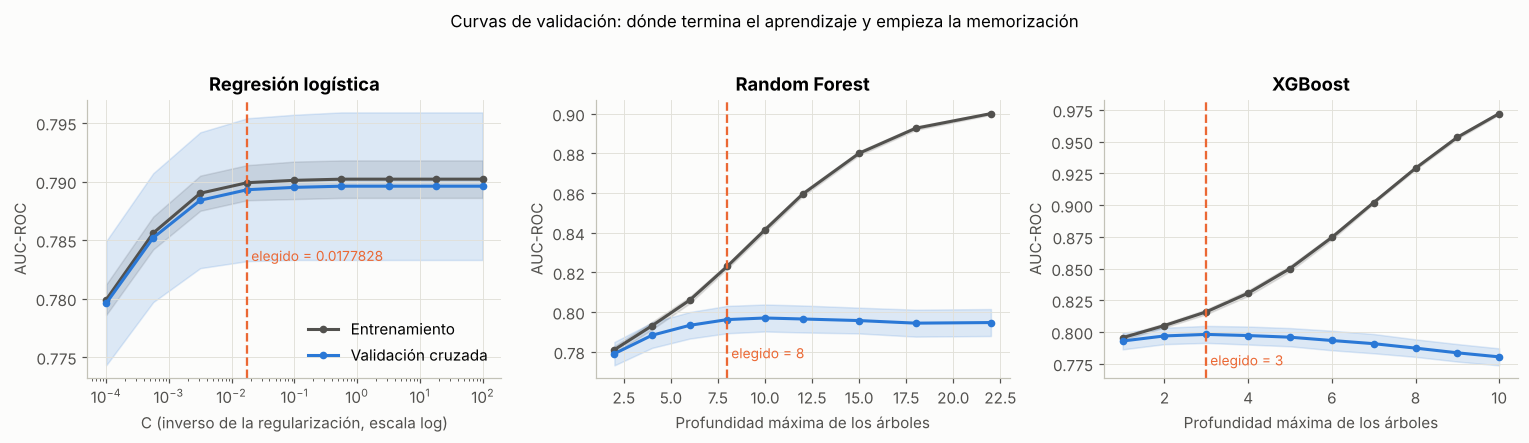

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, (nombre, c) in zip(ejes, curvas_validacion.items()):
    v = np.array(c["valores"])
    for clave, color, rotulo in [("ent", GRIS_OSCURO, "Entrenamiento"), ("val", AZUL, "Validación cruzada")]:
        m, s = np.array(c[f"{clave}_media"]), np.array(c[f"{clave}_std"])
        ax.plot(v, m, marker="o", ms=4, lw=2, color=color, label=rotulo)
        ax.fill_between(v, m - s, m + s, color=color, alpha=0.15)
    ax.axvline(c["elegido"], color=NARANJA, ls="--", lw=1.5)
    ax.text(c["elegido"], ax.get_ylim()[0] + 0.01, f" elegido = {c['elegido']:g}", color=NARANJA, fontsize=9)
    if nombre == "Regresión logística": ax.set_xscale("log")
    ax.set_title(nombre); ax.set_xlabel(c["parametro"]); ax.set_ylabel("AUC-ROC")
ejes[0].legend(loc="lower right")
plt.suptitle("Curvas de validación: dónde termina el aprendizaje y empieza la memorización", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

> 🧭 **Lectura de las curvas de validación**
> - **Regresión logística:** la curva se aplana desde C ≈ 0,018. Relajar la regularización ya no ayuda, y las curvas de entrenamiento y validación casi coinciden: **no hay sobreajuste**. Su límite es la forma lineal del modelo.
> - **Random Forest:** a partir de una profundidad de 8, el AUC de entrenamiento sigue subiendo (hasta 0,90) mientras el de validación se estanca y luego baja. Desde ese punto el bosque empieza a **memorizar**. Se eligió **profundidad 8**.
> - **XGBoost:** el máximo en validación llega con **árboles de apenas 3 niveles**. Con más profundidad, el entrenamiento llega a 0,97 y la validación cae: es sobreajuste clásico. Que basten árboles tan pequeños indica que las relaciones en los datos son **simples, con pocas interacciones**.

In [7]:
# Modelos finales con los hiperparámetros elegidos por las curvas de validación.
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(),
                                         LogisticRegression(C=float(mejores["Regresión logística"]), max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=int(mejores["Random Forest"]),
                                            min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=int(mejores["XGBoost"]), learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEMILLA, verbosity=0),
}
COLOR_MODELO = {"Regresión logística": AZUL, "Random Forest": NARANJA, "XGBoost": AGUA}
for nombre, m in modelos.items():
    print(nombre, "→", m)

Regresión logística → Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.01778279410038923, max_iter=3000))])
Random Forest → RandomForestClassifier(max_depth=8, min_samples_leaf=5, n_estimators=300,
                       n_jobs=-1, random_state=42)
XGBoost → XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=Non

## 3. Validación cruzada: ¿cuánto rinde cada modelo y qué tan estable es?

In [8]:
metricas_cv = {"roc_auc": "AUC-ROC", "accuracy": "Exactitud", "recall": "Sensibilidad",
               "precision": "Precisión", "f1": "F1"}
resultados_cv = {}
for nombre, m in modelos.items():
    r = cross_validate(m, X_ent, y_ent, cv=pliegues, scoring=list(metricas_cv), n_jobs=1)
    resultados_cv[nombre] = {etq: r[f"test_{k}"].round(4).tolist() for k, etq in metricas_cv.items()}
tabla_cv = pd.DataFrame({n: {k: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for k, v in r.items()}
                         for n, r in resultados_cv.items()}).T
tabla_cv

,AUC-ROC,Exactitud,Sensibilidad,Precisión,F1
Regresión logística,0.791 ± 0.003,0.728 ± 0.002,0.668 ± 0.006,0.755 ± 0.004,0.709 ± 0.003
Random Forest,0.798 ± 0.003,0.732 ± 0.004,0.664 ± 0.007,0.763 ± 0.006,0.710 ± 0.004
XGBoost,0.801 ± 0.004,0.736 ± 0.004,0.690 ± 0.005,0.755 ± 0.006,0.721 ± 0.004


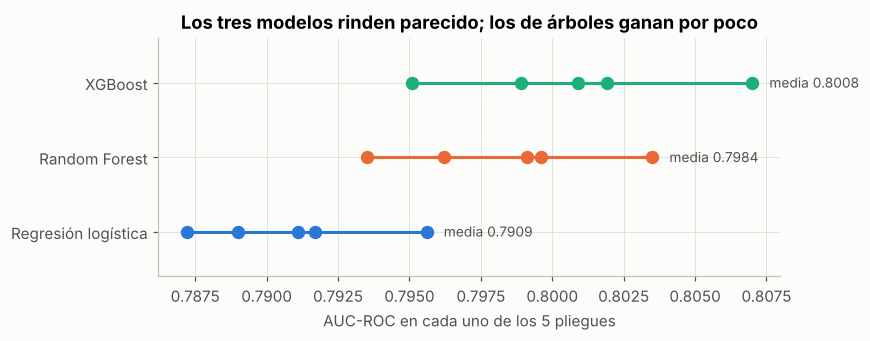

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (nombre, r) in enumerate(resultados_cv.items()):
    auc = np.array(r["AUC-ROC"])
    ax.scatter(auc, [i] * 5, s=60, color=COLOR_MODELO[nombre], zorder=3)
    ax.plot([auc.min(), auc.max()], [i, i], color=COLOR_MODELO[nombre], lw=2)
    ax.text(auc.max() + 0.0006, i, f"media {auc.mean():.4f}", va="center", fontsize=9, color=GRIS_OSCURO)
ax.set_yticks(range(3)); ax.set_yticklabels(resultados_cv.keys()); ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("AUC-ROC en cada uno de los 5 pliegues")
ax.set_title("Los tres modelos rinden parecido; los de árboles ganan por poco")
plt.tight_layout(); plt.show()

## 4. Curvas de aprendizaje: ¿ayudarían más datos?

Una **curva de aprendizaje** entrena el modelo con fracciones crecientes de los datos:
- Si la curva de validación **sigue subiendo** al final, conseguir más datos ayudaría.
- Si ya está **plana** y pegada a la de entrenamiento, el límite está en la *información* que traen las variables, no en la cantidad de pacientes.

Regresión logística  listo en 4s


Random Forest        listo en 86s


XGBoost              listo en 21s


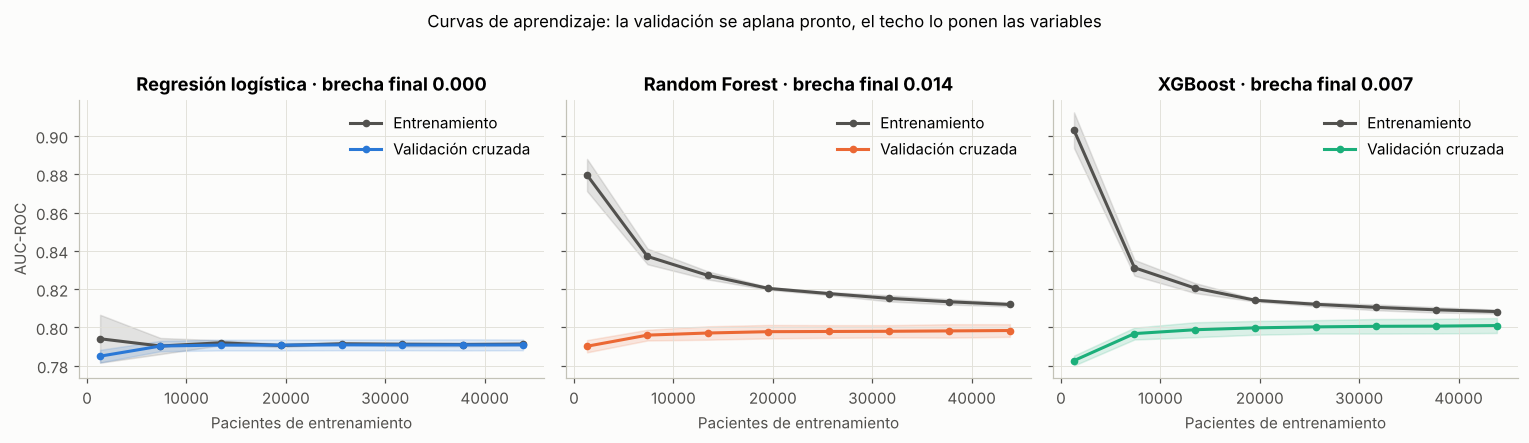

In [10]:
tamanos = np.linspace(0.03, 1.0, 8)
curvas_aprendizaje = {}
for nombre, m in modelos.items():
    t0 = time.time()
    n, ent, val = learning_curve(m, X_ent, y_ent, train_sizes=tamanos, cv=pliegues,
                                 scoring="roc_auc", n_jobs=1, shuffle=True, random_state=SEMILLA)
    curvas_aprendizaje[nombre] = {"n": n.tolist(), "ent_media": ent.mean(1).round(4).tolist(),
        "ent_std": ent.std(1).round(4).tolist(), "val_media": val.mean(1).round(4).tolist(),
        "val_std": val.std(1).round(4).tolist()}
    print(f"{nombre:20s} listo en {time.time()-t0:.0f}s")

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, (nombre, c) in zip(ejes, curvas_aprendizaje.items()):
    n = np.array(c["n"])
    for clave, color, rotulo in [("ent", GRIS_OSCURO, "Entrenamiento"), ("val", COLOR_MODELO[nombre], "Validación cruzada")]:
        mm, s = np.array(c[f"{clave}_media"]), np.array(c[f"{clave}_std"])
        ax.plot(n, mm, marker="o", ms=4, lw=2, color=color, label=rotulo)
        ax.fill_between(n, mm - s, mm + s, color=color, alpha=0.15)
    brecha = c["ent_media"][-1] - c["val_media"][-1]
    ax.set_title(f"{nombre} · brecha final {brecha:.3f}")
    ax.set_xlabel("Pacientes de entrenamiento"); ax.legend(loc="upper right")
ejes[0].set_ylabel("AUC-ROC")
plt.suptitle("Curvas de aprendizaje: la validación se aplana pronto, el techo lo ponen las variables", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

> 🧭 **Lectura de las curvas de aprendizaje**
> - Las tres curvas de validación se **aplanan hacia los 10.000–15.000 pacientes**. Con los casi 55.000 disponibles, más filas apenas moverían el resultado.
> - La brecha entre entrenamiento y validación es mínima: 0,000 en la logística, 0,007 en XGBoost y 0,014 en Random Forest. No hay un problema de varianza.
> - **Conclusión para la sustentación:** el techo de un AUC cercano a 0,80 no lo pone el algoritmo ni la cantidad de datos, sino **la información que traen las variables**. La presión está redondeada, los hábitos son autorreportados y faltan antecedentes familiares, perfil lipídico detallado y tratamientos. Para mejorar se necesitan **mejores variables, no más registros**.

## 5. Evaluación final en el conjunto de prueba

> 🧭 Esta es la **única vez** que los modelos ven los datos de prueba.

In [11]:
probas, filas = {}, []
for nombre, m in modelos.items():
    m.fit(X_ent, y_ent)
    p = m.predict_proba(X_pru)[:, 1]; probas[nombre] = p; pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_pru, pred).ravel()
    filas.append({"Modelo": nombre, "AUC-ROC": roc_auc_score(y_pru, p), "AUC-PR": average_precision_score(y_pru, p),
                  "Exactitud": accuracy_score(y_pru, pred), "Sensibilidad": recall_score(y_pru, pred),
                  "Especificidad": tn / (tn + fp), "Precisión": precision_score(y_pru, pred),
                  "F1": f1_score(y_pru, pred), "Brier": brier_score_loss(y_pru, p)})
tabla_prueba = pd.DataFrame(filas).set_index("Modelo").round(4)
MEJOR = tabla_prueba["AUC-ROC"].idxmax()
print("Mejor modelo por AUC-ROC en prueba:", MEJOR)
tabla_prueba

Mejor modelo por AUC-ROC en prueba: XGBoost


,AUC-ROC,AUC-PR,Exactitud,Sensibilidad,Especificidad,Precisión,F1,Brier
Modelo,,,,,,,,
Regresión logística,0.7943,0.7747,0.7275,0.6666,0.7872,0.7542,0.7077,0.1856
Random Forest,0.8001,0.7819,0.7343,0.6626,0.8045,0.7686,0.7116,0.1817
XGBoost,0.8029,0.7869,0.7357,0.6871,0.7833,0.7565,0.7201,0.1795


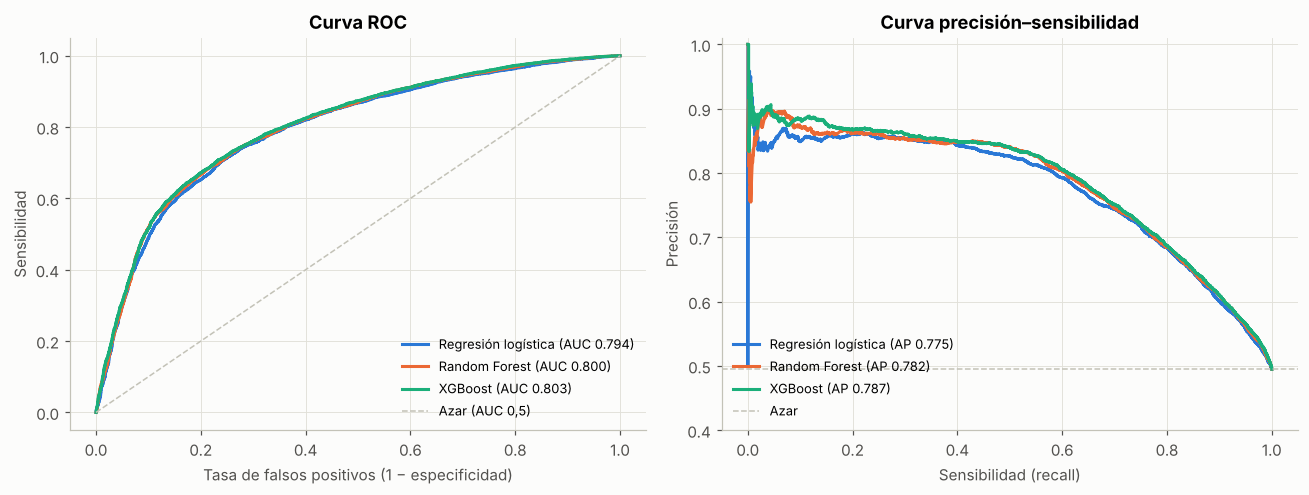

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_pru, p); prec, rec, _ = precision_recall_curve(y_pru, p)
    ejes[0].plot(fpr, tpr, lw=2, color=COLOR_MODELO[nombre], label=f"{nombre} (AUC {roc_auc_score(y_pru, p):.3f})")
    ejes[1].plot(rec, prec, lw=2, color=COLOR_MODELO[nombre], label=f"{nombre} (AP {average_precision_score(y_pru, p):.3f})")
ejes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Azar (AUC 0,5)")
ejes[0].set(xlabel="Tasa de falsos positivos (1 − especificidad)", ylabel="Sensibilidad", title="Curva ROC")
ejes[1].axhline(y_pru.mean(), color=GRIS, ls="--", lw=1, label="Azar")
ejes[1].set(xlabel="Sensibilidad (recall)", ylabel="Precisión", title="Curva precisión–sensibilidad", ylim=(0.4, 1.01))
for ax in ejes: ax.legend(loc="lower left" if ax is ejes[1] else "lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

## 6. Calibración: ¿podemos creerle a la probabilidad?

Un AUC alto dice que el modelo **ordena** bien a los pacientes, pero no que su "70 % de riesgo" signifique un 70 % real. La **curva de calibración** agrupa las predicciones por decil y compara la probabilidad predicha con la proporción observada. La diagonal es la calibración perfecta.

> 🧭 Esto importa porque el dashboard incluye un **simulador** que muestra un porcentaje de riesgo. Si el modelo estuviera mal calibrado, ese número engañaría.

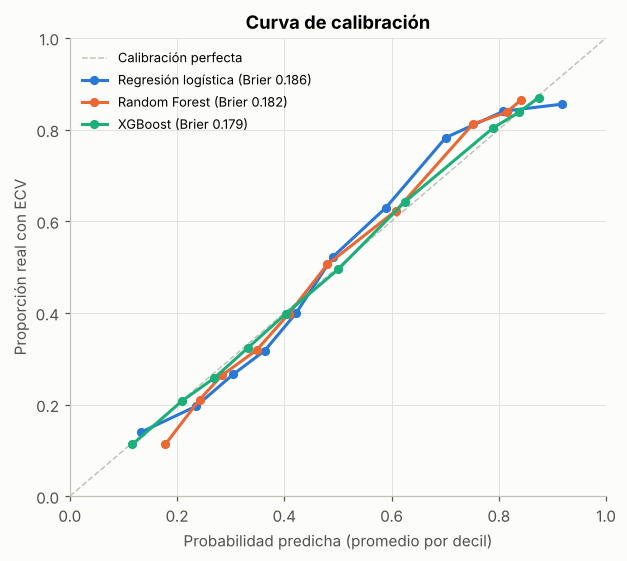

In [13]:
calibracion = {}
fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Calibración perfecta")
for nombre, p in probas.items():
    obs, pred = calibration_curve(y_pru, p, n_bins=10, strategy="quantile")
    calibracion[nombre] = {"predicha": pred.round(4).tolist(), "observada": obs.round(4).tolist(),
                           "brier": round(brier_score_loss(y_pru, p), 4)}
    ax.plot(pred, obs, marker="o", ms=5, lw=2, color=COLOR_MODELO[nombre],
            label=f"{nombre} (Brier {calibracion[nombre]['brier']:.3f})")
ax.set(xlabel="Probabilidad predicha (promedio por decil)", ylabel="Proporción real con ECV",
       title="Curva de calibración", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=8.5); plt.tight_layout(); plt.show()

## 7. El umbral de decisión: una elección clínica, no técnica

Por defecto se clasifica como "con ECV" si la probabilidad es ≥ 0,5. Pero en **tamizaje** (detección temprana), un falso negativo, es decir un enfermo que se va a casa sin seguimiento, suele costar más que un falso positivo, que solo implica un examen adicional.

Comparamos tres criterios:
- **0,5:** el umbral por defecto.
- **Youden:** maximiza sensibilidad + especificidad − 1.
- **Tamizaje:** el umbral más alto que garantiza una sensibilidad ≥ 85 %.

In [14]:
umbrales = np.round(np.arange(0.01, 1.0, 0.01), 2)
def conteos(y_real, p, u):
    pred = p >= u
    return [int((pred & (y_real == 1)).sum()), int((pred & (y_real == 0)).sum()),
            int((~pred & (y_real == 0)).sum()), int((~pred & (y_real == 1)).sum())]   # VP, FP, VN, FN

barrido = {n: [conteos(y_pru, p, u) for u in umbrales] for n, p in probas.items()}

def resumen_umbral(c):
    vp, fp, vn, fn = c
    return {"Sensibilidad": vp / (vp + fn), "Especificidad": vn / (vn + fp),
            "Precisión": vp / (vp + fp) if vp + fp else np.nan, "Falsos negativos": fn, "Falsos positivos": fp}

b = np.array(barrido[MEJOR]); sens = b[:, 0] / (b[:, 0] + b[:, 3]); espe = b[:, 2] / (b[:, 2] + b[:, 1])
U_YOUDEN = float(umbrales[np.argmax(sens + espe - 1)])
U_TAMIZAJE = float(umbrales[np.where(sens >= 0.85)[0].max()])
criterios = {"Por defecto (0,5)": 0.5, f"Youden ({U_YOUDEN})": U_YOUDEN, f"Tamizaje ({U_TAMIZAJE})": U_TAMIZAJE}
pd.DataFrame({k: resumen_umbral(barrido[MEJOR][int(round(u * 100)) - 1]) for k, u in criterios.items()}).T.round(3)

,Sensibilidad,Especificidad,Precisión,Falsos negativos,Falsos positivos
"Por defecto (0,5)",0.687,0.783,0.756,2122.0,1500.0
Youden (0.48),0.709,0.763,0.746,1971.0,1639.0
Tamizaje (0.33),0.853,0.543,0.647,999.0,3161.0


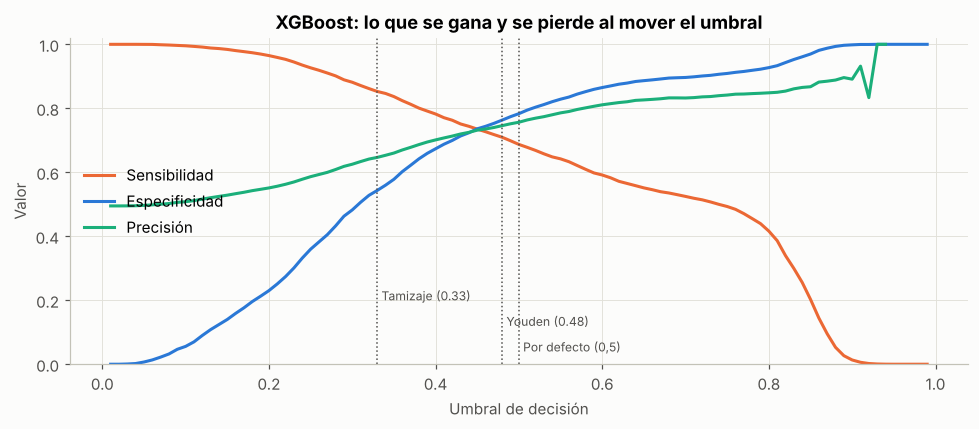

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
precis = np.where(b[:, 0] + b[:, 1] > 0, b[:, 0] / np.maximum(b[:, 0] + b[:, 1], 1), np.nan)
for serie, color, rotulo in [(sens, NARANJA, "Sensibilidad"), (espe, AZUL, "Especificidad"), (precis, AGUA, "Precisión")]:
    ax.plot(umbrales, serie, lw=2, color=color, label=rotulo)
for k, (nombre_c, u) in enumerate(criterios.items()):
    ax.axvline(u, color=GRIS_OSCURO, ls=":", lw=1)
    ax.text(u + 0.005, 0.04 + 0.08 * k, nombre_c, ha="left", fontsize=8, color=GRIS_OSCURO)
ax.set(xlabel="Umbral de decisión", ylabel="Valor", ylim=(0, 1.02), title=f"{MEJOR}: lo que se gana y se pierde al mover el umbral")
ax.legend(loc="center left"); plt.tight_layout(); plt.show()

> 🧭 **Lectura del umbral**
> - Con el umbral por defecto (0,5), XGBoost **deja sin detectar a 2.122 de los cerca de 6.780 pacientes con ECV** del conjunto de prueba, porque su sensibilidad es de 0,69.
> - El umbral de **tamizaje (0,33)** eleva la sensibilidad al 85 % y reduce los falsos negativos a 999, **un 53 % menos**. El costo es que los falsos positivos pasan de 1.500 a 3.161.
> - El umbral de Youden (0,48) queda muy cerca del valor por defecto. Matemáticamente equilibra los dos errores, pero ignora que en tamizaje no cuestan lo mismo.
> - **Recomendación:** para *detección temprana* usar el umbral de 0,33. Para *confirmar* un caso, uno más alto. El dashboard permite mover el umbral y ver este intercambio en vivo.

## 8. Explicabilidad: ¿por qué decide así el modelo?

### 8.1 Regresión logística: coeficientes estandarizados

Como las variables están estandarizadas, cada coeficiente representa el cambio en *log-odds* por **una desviación estándar** de la variable, lo que permite compararlos entre sí.

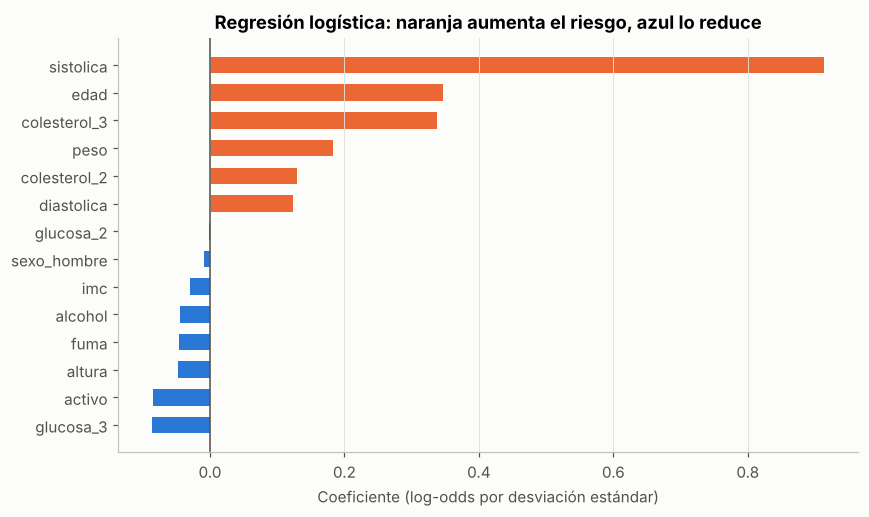

In [16]:
lr = modelos["Regresión logística"]
escalador, logistica = lr.named_steps["standardscaler"], lr.named_steps["logisticregression"]
coef = pd.Series(logistica.coef_[0], index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(coef.index, coef.values, color=[NARANJA if v > 0 else AZUL for v in coef.values], height=0.6)
ax.axvline(0, color=GRIS_OSCURO, lw=1)
ax.set(xlabel="Coeficiente (log-odds por desviación estándar)",
       title="Regresión logística: naranja aumenta el riesgo, azul lo reduce")
ax.grid(axis="y"); plt.tight_layout(); plt.show()

> 🧭 **Precaución con la colinealidad (hallazgo 8 del Cuaderno 01).** El peso, la altura y el IMC están ligados. Cuando la logística los recibe juntos, puede repartir el efecto entre ellos de forma contraintuitiva, por ejemplo con signos opuestos para el peso y el IMC. El modelo *predice* bien, pero esos coeficientes individuales no deben leerse como efectos causales aislados.

### 8.2 SHAP: explicar el modelo de árboles

**SHAP** (*SHapley Additive exPlanations*) reparte cada predicción entre las variables, usando teoría de juegos cooperativos. Cada punto del gráfico es un paciente:
- La posición horizontal indica cuánto empujó esa variable su riesgo hacia arriba o hacia abajo.
- El color indica si el valor de la variable era alto o bajo.

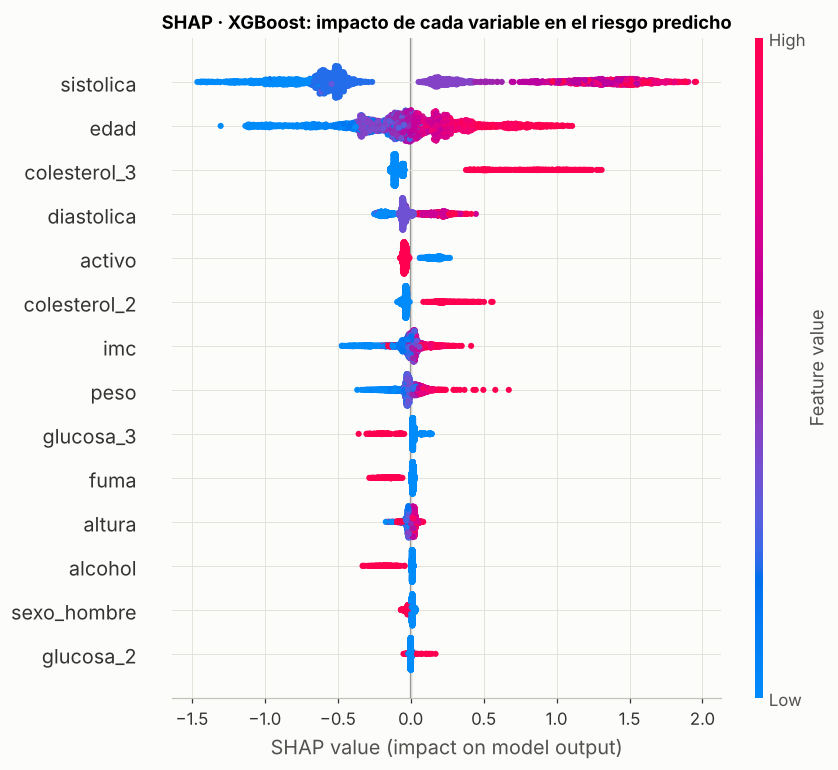

In [17]:
import shap
explicador = shap.TreeExplainer(modelos["XGBoost"])
muestra_shap = X_pru.sample(3000, random_state=SEMILLA)
valores_shap = explicador(muestra_shap)
shap.plots.beeswarm(valores_shap, max_display=14, show=False)
plt.title("SHAP · XGBoost: impacto de cada variable en el riesgo predicho"); plt.tight_layout(); plt.show()

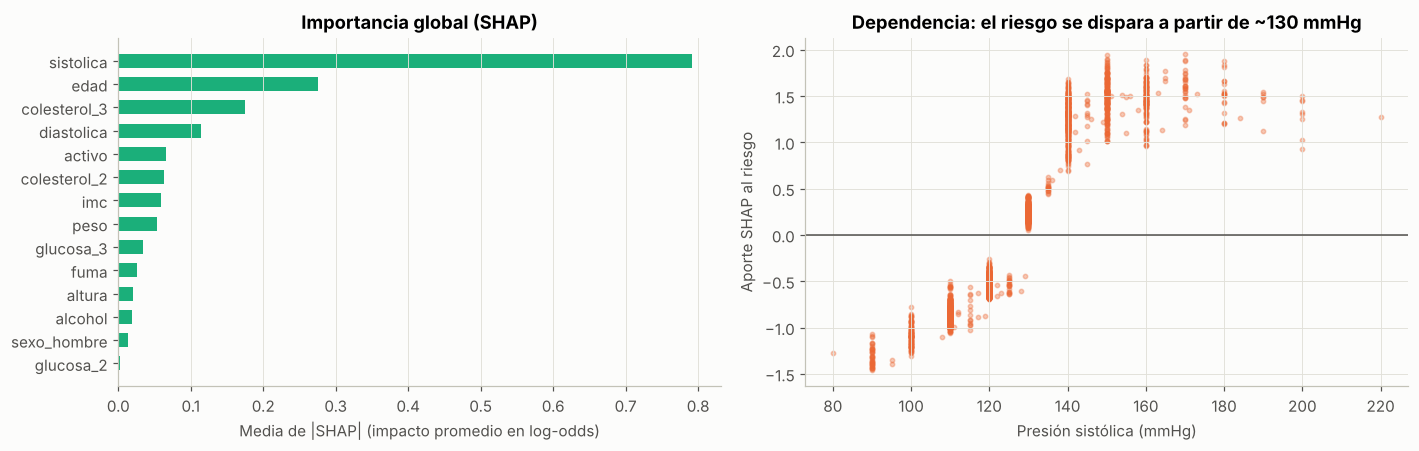

In [18]:
importancia_shap = pd.Series(np.abs(valores_shap.values).mean(0), index=VARIABLES).sort_values(ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
imp = importancia_shap[::-1]
ejes[0].barh(imp.index, imp.values, color=AGUA, height=0.6); ejes[0].grid(axis="y")
ejes[0].set(xlabel="Media de |SHAP| (impacto promedio en log-odds)", title="Importancia global (SHAP)")
# Dependencia: cómo cambia el aporte de la sistólica según su valor (los "escalones" son la preferencia de dígito).
ejes[1].scatter(muestra_shap["sistolica"], valores_shap[:, "sistolica"].values, s=8, alpha=0.35, color=NARANJA)
ejes[1].axhline(0, color=GRIS_OSCURO, lw=1)
ejes[1].set(xlabel="Presión sistólica (mmHg)", ylabel="Aporte SHAP al riesgo",
            title="Dependencia: el riesgo se dispara a partir de ~130 mmHg")
plt.tight_layout(); plt.show()

> 🧭 **Lectura de la explicabilidad**
> - **Los dos modelos coinciden.** La **presión sistólica domina**: su impacto promedio (0,79) triplica el de la edad (0,27). Le siguen el colesterol muy alto y la diastólica. Esto confirma lo que anticipó el EDA.
> - **El modelo redescubrió la guía clínica.** En el gráfico de dependencia, el aporte de la sistólica pasa de negativo a positivo justo alrededor de **130 mmHg**, el umbral de hipertensión estadio 1 de la ACC/AHA. Nadie se lo enseñó.
> - Los **"escalones"** del gráfico de dependencia son la preferencia de dígito: el modelo solo ve valores como 120, 130 o 140.
> - **Señales contraintuitivas.** En ambos modelos, la glucosa muy alta, fumar y el alcohol *reducen* levemente el riesgo predicho. Esto **no es causal**. Las explicaciones probables son:
>   - El subreporte de los hábitos.
>   - Que la glucosa alta comparte información con el colesterol muy alto (correlación 0,48), que se "lleva" el efecto.
>   - Que los pacientes diagnosticados podrían estar en tratamiento.
>
>   El modelo aprende **asociaciones de este conjunto de datos, no causas**. Esto se declara en la ficha del modelo.

## 9. Equidad: ¿el modelo funciona igual para todos?

Un modelo puede tener buen rendimiento global y fallar más en un subgrupo. Comparamos las métricas del mejor modelo por **sexo** y por **grupo de edad**, usando el umbral de tamizaje.

In [19]:
d_pru = d_pru.assign(prob=probas[MEJOR], real=y_pru,
                     grupo_edad=pd.cut(d_pru.edad, [29, 45, 55, 66], labels=["30–44", "45–54", "55–65"], right=False))
def metricas_grupo(g, u):
    pred = g.prob >= u; vp = (pred & (g.real == 1)).sum(); fn = (~pred & (g.real == 1)).sum()
    vn = (~pred & (g.real == 0)).sum(); fp = (pred & (g.real == 0)).sum()
    return pd.Series({"n": len(g), "Prevalencia": g.real.mean(), "AUC-ROC": roc_auc_score(g.real, g.prob),
                      "Sensibilidad": vp / (vp + fn), "Especificidad": vn / (vn + fp), "Tasa de alerta": pred.mean()})
tabla_equidad = pd.concat({
    "Sexo": d_pru.groupby("sexo").apply(metricas_grupo, u=U_TAMIZAJE),
    "Edad": d_pru.groupby("grupo_edad", observed=True).apply(metricas_grupo, u=U_TAMIZAJE)}).round(3)
tabla_equidad

n  Prevalencia  AUC-ROC  Sensibilidad  Especificidad  \
Sexo Hombre  4801.0        0.503    0.796         0.849          0.532   
     Mujer   8902.0        0.491    0.806         0.855          0.549   
Edad 30–44   1917.0        0.285    0.823         0.628          0.893   
     45–54   5562.0        0.446    0.790         0.731          0.714   
     55–65   6224.0        0.603    0.751         0.965          0.136   

             Tasa de alerta  
Sexo Hombre           0.659  
     Mujer            0.649  
Edad 30–44            0.256  
     45–54            0.485  
     55–65            0.925

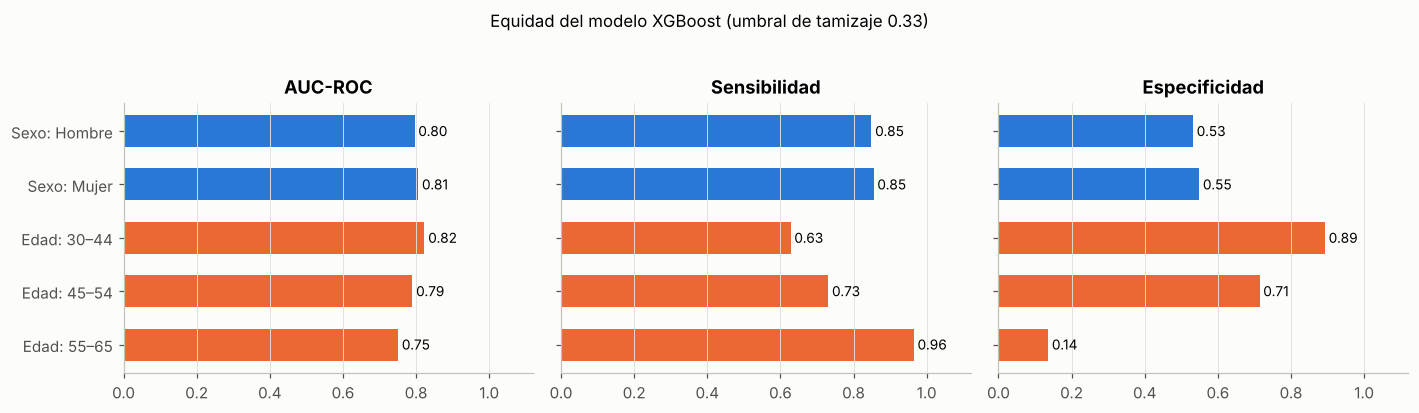

In [20]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, metrica in zip(ejes, ["AUC-ROC", "Sensibilidad", "Especificidad"]):
    etiquetas = [f"{a}: {b}" for a, b in tabla_equidad.index]
    colores = [AZUL if a == "Sexo" else NARANJA for a, _ in tabla_equidad.index]
    ax.barh(etiquetas, tabla_equidad[metrica], color=colores, height=0.6)
    for i, v in enumerate(tabla_equidad[metrica]): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
    ax.set_xlim(0, 1.12); ax.set_title(metrica); ax.grid(axis="y")
ejes[0].invert_yaxis()
plt.suptitle(f"Equidad del modelo {MEJOR} (umbral de tamizaje {U_TAMIZAJE})", y=1.03, fontsize=11)
plt.tight_layout(); plt.show()

> 🧭 **Lectura de la equidad: el hallazgo más importante del proyecto**
> - **Por sexo hay paridad.** El AUC es de 0,80 en hombres y 0,81 en mujeres, con la misma sensibilidad (0,85).
> - **Por edad hay una disparidad fuerte.** Con un umbral único:
>   - Al grupo de **55 a 65 años** el modelo le da alerta al **92,5 %** de los pacientes, con una especificidad de apenas 0,14. Casi todos son "positivos".
>   - En el grupo de **30 a 44 años** pierde al **37 %** de los pacientes que sí tienen ECV (sensibilidad 0,63).
> - **¿Por qué?** El modelo se apoya mucho en la edad. Un joven con ECV "no parece" enfermo para el modelo, y un mayor sano "parece" enfermo.
> - **Cómo mitigarlo:** usar umbrales diferenciados por grupo de edad, recalibrar por subgrupo o, si fuera posible, agregar variables que discriminen dentro de cada grupo. El dashboard permite explorar el umbral por subgrupo.
> - **Lección:** un buen AUC global (0,80) **puede esconder** un desempeño muy desigual. La equidad hay que medirla, no suponerla.

## 10. Ficha del modelo (*Model Card*)

| Campo | Contenido |
|---|---|
| **Modelo** | XGBoost (300 árboles, profundidad 3, tasa de aprendizaje 0,05). Para el simulador se usa la regresión logística, más transparente, que rinde solo 0,9 puntos de AUC menos. |
| **Datos** | 68.512 exámenes de adultos de 30 a 65 años (Kaggle, S. Ulianova), limpiados con 7 reglas clínicas. El origen geográfico y el periodo de recolección no están documentados. |
| **Rendimiento (prueba, n = 13.703)** | AUC-ROC 0,803 · exactitud 0,736 · Brier 0,180 (bien calibrado). |
| **Umbral recomendado** | 0,33 para tamizaje: sensibilidad 0,85 y especificidad 0,54. |
| **Uso previsto** | Fines educativos y exploración de factores de riesgo. Como máximo, apoyo para **priorizar** a quién hacer un tamizaje más completo. |
| **No usar para** | Diagnosticar, decidir tratamientos, ni aplicar a menores de 30, mayores de 65 o poblaciones distintas sin revalidar. |
| **Limitaciones** | Presión registrada con redondeo. Hábitos autorreportados. Sin antecedentes familiares ni tratamientos. Las asociaciones aprendidas no son causales (glucosa, tabaco y alcohol muestran efectos contraintuitivos). |
| **Equidad** | Paridad por sexo. **Disparidad marcada por edad** con un umbral único: sobrealerta en 55–65 años y subdetección en 30–44 años. |
| **Consideraciones éticas** | Un falso negativo puede retrasar la atención y un falso positivo genera ansiedad y costos. Toda decisión clínica corresponde a un profesional de la salud. |

## 11. Exportar resultados para el dashboard

In [21]:
def submuestrear(x, yv, n=150):
    idx = np.unique(np.linspace(0, len(x) - 1, n).astype(int)); return np.round(x[idx], 4).tolist(), np.round(yv[idx], 4).tolist()

curvas_roc, curvas_pr = {}, {}
for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_pru, p); curvas_roc[nombre] = dict(zip(["fpr", "tpr"], submuestrear(fpr, tpr)))
    prec, rec, _ = precision_recall_curve(y_pru, p); curvas_pr[nombre] = dict(zip(["recall", "precision"], submuestrear(rec[::-1], prec[::-1])))

# Barrido de umbral por subgrupo (para el deslizador de equidad del dashboard).
barrido_grupos = {}
for col in ["sexo", "grupo_edad"]:
    for nivel, g in d_pru.groupby(col, observed=True):
        barrido_grupos[f"{col}:{nivel}"] = {"n": int(len(g)), "auc": round(roc_auc_score(g.real, g.prob), 4),
                                           "conteos": [conteos(g.real.values, g.prob.values, u) for u in umbrales]}

# Parámetros del simulador: la regresión logística completa (escalado + coeficientes) cabe en unos pocos números.
simulador = {"variables": VARIABLES, "media": escalador.mean_.round(6).tolist(), "escala": escalador.scale_.round(6).tolist(),
             "coef": logistica.coef_[0].round(6).tolist(), "intercepto": round(float(logistica.intercept_[0]), 6),
             "auc_prueba": float(tabla_prueba.loc["Regresión logística", "AUC-ROC"])}

modelos_json = {
    "mejor": MEJOR, "hiperparametros": {k: float(v) for k, v in mejores.items()},
    "curvas_validacion": curvas_validacion, "curvas_aprendizaje": curvas_aprendizaje,
    "cv": resultados_cv, "prueba": tabla_prueba.reset_index().to_dict(orient="records"),
    "roc": curvas_roc, "pr": curvas_pr, "calibracion": calibracion,
    "umbral": {"valores": umbrales.tolist(), "conteos": barrido, "youden": U_YOUDEN, "tamizaje": U_TAMIZAJE},
    "equidad": barrido_grupos,
    "importancia": {"shap": importancia_shap.round(4).to_dict(),
                    "coef_logistica": dict(zip(VARIABLES, logistica.coef_[0].round(4).tolist()))},
    "simulador": simulador, "n_prueba": int(len(y_pru)), "prevalencia_prueba": round(float(y_pru.mean()), 4),
}
with open(RES("modelos.json"), "w", encoding="utf-8") as f:
    json.dump(modelos_json, f, ensure_ascii=False)
ARCHIVOS_EXPORTADOS = [RES("modelos.json")]
print(f"modelos.json: {os.path.getsize(RES('modelos.json'))/1024:.0f} KB")
print("Hiperparámetros para el Cuaderno 03:", {k: float(v) for k, v in mejores.items()})

modelos.json: 40 KB
Hiperparámetros para el Cuaderno 03: {'Regresión logística': 0.01778279410038923, 'Random Forest': 8.0, 'XGBoost': 3.0}


In [22]:
# Descarga de resultados (solo en Colab). Estos JSON alimentan el dashboard interactivo.
try:
    from google.colab import files
    for archivo in ARCHIVOS_EXPORTADOS:
        files.download(archivo)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta", RESULTADOS)

Fuera de Colab: los archivos quedaron en la carpeta ../resultados
